# Quantitative tilt tolerancing of a vectorial off-axis parabolic mirror

This notebook builds the OAP focus **from scratch**, following the geometry step by
step, and uses it to answer a quantitative question: **how much OAP tilt can we
tolerate before the focus stops being diffraction-limited?**

It differs from the illustrative version in one important way: the incident field is
placed on the mirror by an **exact closed-form ray/surface intersection**, so the
*parent-pupil-coordinate approximation is not used here*. That matters for
tolerancing, where we need the wavefront (not just a pretty PSF).

**Pipeline.** For each incident ray:

$$
\text{ray} \xrightarrow{\text{intersect}} \mathbf r_m,(x_p,y_p)
\xrightarrow{\text{reflect}} \hat{\mathbf e}_r,\mathbf E_r
\xrightarrow{\text{apodise + Jacobian}} \text{angular spectrum}
\xrightarrow{\text{Debye sum}} \mathbf E(v,w).
$$

The focal field is the Debye–Wolf transform of the field on the reference sphere,
$$
\boxed{\;\mathbf E(v,w)=\iint P(k_v,k_w)\,e^{\,i(k_v v + k_w w)}\,dk_v\,dk_w\;}
$$
and everything below is about building $P$ correctly and reading the **wavefront
phase** out of it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

# ---------- system parameters ----------
F    = 7.5e-3       # PARENT focal length [m]  (NOT the 15 mm reflected focal length!)
LAM  = 1030e-9      # wavelength [m]
APER = 12.7e-3      # clear aperture diameter [m]
K    = 2*np.pi/LAM  # wavenumber [1/m]
E_I  = np.array([0., 0., -1.])   # incident propagation direction (fixed lab beam)

theta_max = np.arctan((APER/2)/(2*F))
NA = np.sin(theta_max)
print(f"NA = {NA:.3f}   f/# = {2*F/APER:.2f}   theta_max = {np.degrees(theta_max):.1f} deg")
print(f"diffraction spot scale  lambda/(2NA) = {LAM/(2*NA)*1e6:.2f} um")

NA = 0.390   f/# = 1.18   theta_max = 22.9 deg
diffraction spot scale  lambda/(2NA) = 1.32 um


## 1. Geometry: surface and normal

**Parent paraboloid** with parent focal length $f$:
$$
z_p=\frac{x_p^2+y_p^2}{4f}.
$$
Writing the surface as a level set $F=z_p-\tfrac{x_p^2+y_p^2}{4f}=0$, the normal is
parallel to $\nabla F=(-x_p/2f,\,-y_p/2f,\,1)$, so
$$
\hat{\mathbf n}_p=\frac{(-x_p/2f,\,-y_p/2f,\,1)}{\sqrt{1+(x_p^2+y_p^2)/4f^2}} .
$$
Tilt/decenter is a **rigid transform** $\mathbf r_{\text{lab}}=R\,\mathbf r_p+\mathbf t$,
under which the normal simply rotates, $\hat{\mathbf n}_{\text{lab}}=R\,\hat{\mathbf n}_p$.

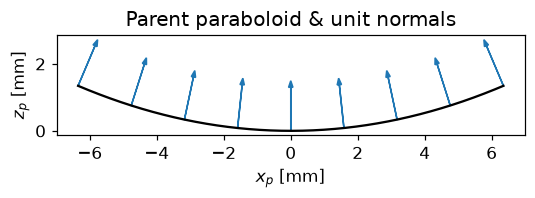

control  max| |n|-1 | = 2.220446049250313e-16


In [2]:
def rotation_matrix(axis, ang):
    a = np.asarray(axis, float); a = a/np.linalg.norm(a)
    Kx = np.array([[0,-a[2],a[1]],[a[2],0,-a[0]],[-a[1],a[0],0]])
    return np.eye(3) + np.sin(ang)*Kx + (1-np.cos(ang))*(Kx@Kx)

def z_parent(xp, yp):
    return (xp**2 + yp**2)/(4*F)

def normal_parent(xp, yp):
    n = np.stack([-xp/(2*F), -yp/(2*F), np.ones_like(np.asarray(xp, float))], axis=-1)
    return n/np.linalg.norm(n, axis=-1, keepdims=True)

# visual check: parabola profile + a few unit normals
xx = np.linspace(-APER/2, APER/2, 200)
plt.figure(figsize=(5,2.8))
plt.plot(xx*1e3, z_parent(xx,0)*1e3, 'k')
for x0 in np.linspace(-APER/2, APER/2, 9):
    n = normal_parent(x0, 0.0); z0 = z_parent(x0, 0.0)
    plt.arrow(x0*1e3, z0*1e3, n[0]*1.3, n[2]*1.3, head_width=0.13, color='C0', lw=1)
plt.gca().set_aspect('equal'); plt.xlabel('$x_p$ [mm]'); plt.ylabel('$z_p$ [mm]')
plt.title('Parent paraboloid & unit normals'); plt.tight_layout(); plt.show()

xr, yr = np.random.randn(2, 2000)*3e-3
print("control  max| |n|-1 | =", np.abs(np.linalg.norm(normal_parent(xr,yr),axis=-1)-1).max())

## 2. Exact ray/surface intersection (no pupil approximation)

A collimated ray enters at transverse $(X_{\text{in}},Y_{\text{in}})$ and travels
along $\hat{\mathbf e}_i=-\hat{\mathbf z}$. We must find **where it hits the tilted
surface** and sample the input field at the ray's own transverse coordinate.

Transform the ray $\mathbf r(s)=\mathbf r_{\text{in}}+s\,\hat{\mathbf e}_i$ into the
parent frame, $\mathbf r_p(s)=\mathbf a+s\,\mathbf d$ with
$\mathbf a=R^{\top}(\mathbf r_{\text{in}}-\mathbf t)$, $\mathbf d=R^{\top}\hat{\mathbf e}_i$.
Imposing $z_p=(x_p^2+y_p^2)/4f$ gives a **quadratic** $A s^2+Bs+C=0$:
$$
A=\frac{d_x^2+d_y^2}{4f},\quad
B=\frac{2(a_xd_x+a_yd_y)}{4f}-d_z,\quad
C=\frac{a_x^2+a_y^2}{4f}-a_z .
$$
Take the first-hit root. The plot below shows exactly what the old approximation got
wrong: the distance between the parent coordinate $(x_p,y_p)$ and the ray's true
transverse coordinate $(X_{\text{in}},Y_{\text{in}})$.

control  on-surface residual   : 4.2832978917189957e-14
control  r_m == R r_p + t (err): 6.938893903907228e-18


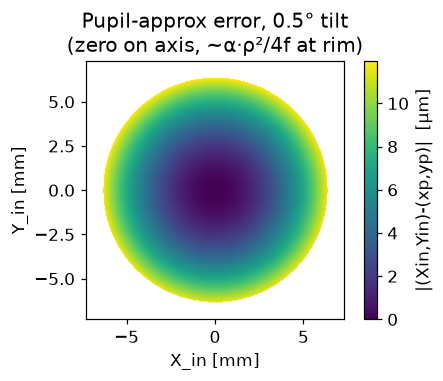

max mis-sampling at rim = 12.0 µm  (this is what we now avoid)


In [6]:
def intersect(Xin, Yin, zin, R, t):
    Rt = R.T
    d = Rt @ E_I
    rin = np.stack([Xin, Yin, np.full_like(Xin, zin)], axis=-1)
    a = (rin - t) @ Rt.T
    ax, ay, az = a[...,0], a[...,1], a[...,2]
    dx, dy, dz = d
    A = (dx**2+dy**2)/(4*F)
    B = 2*(ax*dx+ay*dy)/(4*F) - dz
    C = (ax**2+ay**2)/(4*F) - az
    if abs(A) < 1e-14:                       # aligned -> linear
        s = -C/B
    else:
        disc = np.sqrt(np.maximum(B**2 - 4*A*C, 0.0))
        s1 = (-B - disc)/(2*A); s2 = (-B + disc)/(2*A)
        s = np.where((s1 > 0) & ((s1 < s2) | (s2 <= 0)), s1, s2)   # first hit
    r_p = a + s[...,None]*d
    r_m = rin + s[...,None]*E_I              # equals R r_p + t
    return r_p[...,0], r_p[...,1], r_p, r_m

# ---- worked example threaded through the notebook: a 0.1 deg tilt about x ----
TILT_DEG = 0.5
R = rotation_matrix((1,0,0), np.deg2rad(TILT_DEG)); t = np.zeros(3); zin = 0.05
pix = 260; Lpup = 1.15*APER
xi = (np.arange(pix) - pix/2)*(Lpup/pix)
Xin, Yin = np.meshgrid(xi, xi, indexing='xy')
dA = (Lpup/pix)**2

xp, yp, r_p, r_m = intersect(Xin, Yin, zin, R, t)
inside = (xp**2 + yp**2) <= (APER/2)**2

print("control  on-surface residual   :", np.abs(z_parent(xp,yp)-r_p[...,2])[inside].max())
print("control  r_m == R r_p + t (err):", np.abs(r_m - (r_p@R.T + t))[inside].max())

miss = np.hypot(Xin - xp, Yin - yp)          # the mis-sampling the approximation made
ext = [-Lpup/2*1e3, Lpup/2*1e3, -Lpup/2*1e3, Lpup/2*1e3]
plt.figure(figsize=(4.5,3.6))
im = plt.imshow(np.where(inside, miss*1e6, np.nan), origin='lower', extent=ext, cmap='viridis')
plt.colorbar(im, label='|(Xin,Yin)-(xp,yp)|  [µm]')
plt.xlabel('X_in [mm]'); plt.ylabel('Y_in [mm]')
plt.title(f'Pupil-approx error, {TILT_DEG}° tilt\n(zero on axis, ~α·ρ²/4f at rim)')
plt.tight_layout(); plt.show()
print(f"max mis-sampling at rim = {miss[inside].max()*1e6:.1f} µm  (this is what we now avoid)")

## 3. Reflection

**Direction** (Householder reflection, preserves length):
$$
\hat{\mathbf e}_r=\hat{\mathbf e}_i-2(\hat{\mathbf e}_i\!\cdot\!\hat{\mathbf n})\hat{\mathbf n}.
$$
**Field** (ideal conductor; isolate this to swap in Fresnel $s/p$ later):
$$
\mathbf E_r=-\mathbf E_i+2(\mathbf E_i\!\cdot\!\hat{\mathbf n})\hat{\mathbf n},
\qquad \hat{\mathbf e}_r\!\cdot\!\mathbf E_r=-(\hat{\mathbf e}_i\!\cdot\!\mathbf E_i),
$$
so a transverse input stays transverse after reflection.

In [7]:
def reflect_dir(e_i, n):
    return e_i - 2*np.sum(e_i*n, axis=-1, keepdims=True)*n

def reflect_field(E, n):
    return -E + 2*np.sum(E*n, axis=-1, keepdims=True)*n

n_lab = normal_parent(xp, yp) @ R.T
e_r = reflect_dir(E_I, n_lab)

POL = np.array([0., 1., 0.])                 # y-polarised input
print("control  max| |e_r|-1 |        :", np.abs(np.linalg.norm(e_r,axis=-1)-1)[inside].max())
E_unit = np.broadcast_to(POL, e_r.shape)
print("control  max|E_r . e_r| (transv):", np.abs(np.sum(reflect_field(E_unit,n_lab)*e_r,axis=-1))[inside].max())

control  max| |e_r|-1 |        : 1.1102230246251565e-15
control  max|E_r . e_r| (transv): 6.106226635438361e-16


## 4. Focusing map, apodisation, and the flux Jacobian

Let $\theta$ be the ray angle from the output axis, $\cos\theta=\hat{\mathbf e}_r\!\cdot\!\hat{\mathbf u}$.
Two **separate** weights turn the reflected field into the angular spectrum:

* **Physical apodisation** (energy conservation on the parabola):
  $q(\theta)=\sec^2(\theta/2)=2/(1+\cos\theta)$.
* **Solid-angle ↔ k-space Jacobian:** $d\Omega=\dfrac{dk_v\,dk_w}{k\,k_u}$.

Because we integrate over the *incident-beam area* $dA_{\text{in}}$, the two combine into
a single **energy-conserving amplitude weight** per ray,
$$
\text{weight}=\sqrt{\;\underbrace{\frac{d\Omega}{dA_{\text{in}}}}_{J}\;},
\qquad
J=\frac{\bigl|\det\partial(k_v,k_w)/\partial(X_{\text{in}},Y_{\text{in}})\bigr|}{k\,k_u},
$$
which we obtain by finite-differencing the (smooth) map $(X_{\text{in}},Y_{\text{in}})\!\to\!(k_v,k_w)$.
The control below checks $J$ against the closed form $\cos^4(\theta/2)/f^2$ on the
aligned mirror.

control  J_numeric / J_analytic (aligned): mean=0.99998  scatter=4.8e-06


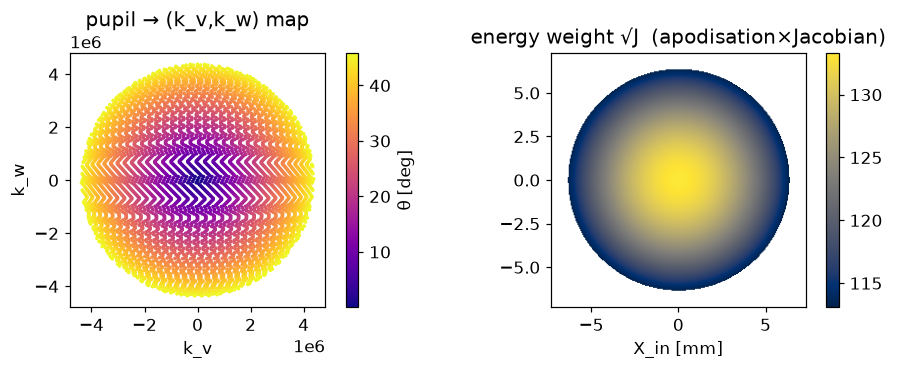

In [8]:
def output_basis(e_r_inside):
    u = e_r_inside.mean(0); u /= np.linalg.norm(u)          # track the chief/mean ray
    ref = np.array([0,0,1.]) if abs(u[2]) < 0.9 else np.array([1,0,0.])
    v = ref - np.dot(ref,u)*u; v /= np.linalg.norm(v)
    w = np.cross(u, v)
    return u, v, w

def flux_jacobian(kv, kw, ku, xi):
    dkv_dy, dkv_dx = np.gradient(kv, xi, xi)
    dkw_dy, dkw_dx = np.gradient(kw, xi, xi)
    det = np.abs(dkv_dx*dkw_dy - dkv_dy*dkw_dx)
    return det/(K*np.maximum(ku, 1e-9))

u,v,w = output_basis(e_r[inside])
kv = K*(e_r@v); kw = K*(e_r@w); ku = K*(e_r@u)
Jflux = flux_jacobian(kv, kw, ku, xi)
weight = np.sqrt(np.maximum(Jflux, 0.0))

# ---- control: aligned mirror, u=+z, compare J to cos^4(theta/2)/f^2 ----
xp0,yp0,_,_ = intersect(Xin, Yin, zin, np.eye(3), t)
ins0 = (xp0**2+yp0**2) <= (APER/2)**2
e_r0 = reflect_dir(E_I, normal_parent(xp0,yp0))
kv0,kw0,ku0 = K*e_r0[...,0], K*e_r0[...,1], K*e_r0[...,2]
J0 = flux_jacobian(kv0, kw0, ku0, xi)
cos_tp = (4*F**2-(xp0**2+yp0**2))/(4*F**2+(xp0**2+yp0**2))
J_analytic = ((1+cos_tp)/2)**2 / F**2
ratio = (J0/J_analytic)[ins0]
print(f"control  J_numeric / J_analytic (aligned): mean={ratio.mean():.5f}  "
      f"scatter={ratio.std()/ratio.mean():.1e}")

fig,ax = plt.subplots(1,2, figsize=(9,3.4))
sc = ax[0].scatter((kv[inside])[::7], (kw[inside])[::7], s=2,
                   c=np.degrees(np.arccos(np.clip(ku[inside]/K,-1,1)))[::7], cmap='plasma')
ax[0].set_title('pupil → (k_v,k_w) map'); ax[0].set_xlabel('k_v'); ax[0].set_ylabel('k_w')
ax[0].set_aspect('equal'); plt.colorbar(sc, ax=ax[0], label='θ [deg]')
im = ax[1].imshow(np.where(inside, weight, np.nan), origin='lower', extent=ext, cmap='cividis')
ax[1].set_title('energy weight √J  (apodisation×Jacobian)')
ax[1].set_xlabel('X_in [mm]'); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## 5. The wavefront (optical path) — the quantity tolerancing lives on

Along each reflected ray the optical path to the focal reference is
$$
L=\underbrace{(\mathbf r_m-\mathbf p_{\text{ref}})\!\cdot\!\hat{\mathbf e}_i}_{L_{\text{in}}}
+\underbrace{\hat{\mathbf e}_r\!\cdot\!(\mathbf F-\mathbf r_m)}_{\text{to plane through }\mathbf F},
\qquad \varphi_{\text{OPD}}=k\,(L-\langle L\rangle).
$$
For the aligned parabola $L$ is constant (perfect focus); a tilt makes its cubic part
**coma**.

**Where is $\mathbf F$?** A tilted mirror with a fixed input beam has *no* stigmatic
focus, and the rigidly-transformed point $R(0,0,f)+\mathbf t$ is **wrong** (it injects
hundreds of waves of spurious tilt). We use the least-squares crossing of the reflected
rays, which minimises $\sum_i\lVert(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})(\mathbf F-\mathbf r_{m,i})\rVert^2$:
$$
\Big[\textstyle\sum_i(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})\Big]\mathbf F
=\sum_i(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})\mathbf r_{m,i}.
$$

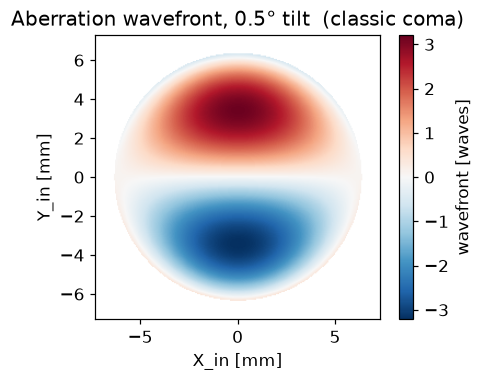

coma PtV = 6.38 waves


In [9]:
def ls_focus(e_r_in, r_m_in):
    P = np.eye(3) - e_r_in[:,:,None]*e_r_in[:,None,:]
    return np.linalg.solve(P.sum(0), np.einsum('nij,nj->i', P, r_m_in))

def opd_phase(e_r, r_m, Fpt, inside, zin):
    L_in  = np.sum((r_m - np.array([0.,0.,zin]))*E_I, axis=-1)
    L_out = np.sum(e_r*(Fpt - r_m), axis=-1)
    L = L_in + L_out
    return K*(L - L[inside].mean())

Fpt = ls_focus(e_r[inside], r_m[inside])
phi = opd_phase(e_r, r_m, Fpt, inside, zin)

W = np.where(inside, phi/(2*np.pi), np.nan)          # wavefront in WAVES
plt.figure(figsize=(4.5,3.6))
im = plt.imshow(W, origin='lower', extent=ext, cmap='RdBu_r',
                vmin=-np.nanmax(np.abs(W)), vmax=np.nanmax(np.abs(W)))
plt.colorbar(im, label='wavefront [waves]')
plt.xlabel('X_in [mm]'); plt.ylabel('Y_in [mm]')
plt.title(f'Aberration wavefront, {TILT_DEG}° tilt  (classic coma)')
plt.tight_layout(); plt.show()
print(f"coma PtV = {np.nanmax(W)-np.nanmin(W):.2f} waves")

## 6. The Debye sum

Each component transforms independently (the kernel is scalar):
$$
E_{x,y,z}(v,w)=\sum_{\text{rays}} \big[\mathbf E_r\big]_{x,y,z}\,\sqrt{J}\;e^{i\varphi_{\text{OPD}}}\;
e^{\,i(k_v v+k_w w)}\,dA_{\text{in}},
\qquad I=|E_x|^2+|E_y|^2+|E_z|^2 .
$$
Evaluated as a **non-uniform DFT** (two dense matmuls) — exact, no scattered
interpolation. We wrap the whole chain into one function and validate that the aligned
case gives a centred, Strehl-1 focus.

In [10]:
def debye(col, kvf, kwf, vax, wax):
    Mv = np.exp(1j*np.outer(vax, kvf)); Mw = np.exp(1j*np.outer(wax, kwf))
    return ((Mv*col[None,:]) @ Mw.T).T

def exact_oap(field_fn, tilt_deg, pol=(0,1,0), pix=260, pupil_pad=1.15,
              zin=0.05, Lout=40e-6, Nout=160):
    R = rotation_matrix((1,0,0), np.deg2rad(tilt_deg)) if tilt_deg else np.eye(3)
    t = np.zeros(3)
    Lp = pupil_pad*APER
    xi = (np.arange(pix)-pix/2)*(Lp/pix); dA = (Lp/pix)**2
    Xin, Yin = np.meshgrid(xi, xi, indexing='xy')
    xp, yp, r_p, r_m = intersect(Xin, Yin, zin, R, t)
    inside = (xp**2+yp**2) <= (APER/2)**2

    n_lab = normal_parent(xp, yp) @ R.T
    e_r = reflect_dir(E_I, n_lab)
    Ein = field_fn(Xin, Yin)                      # sampled at the ray's OWN coordinate
    p = np.asarray(pol, float); p /= np.linalg.norm(p)
    E_r = reflect_field(Ein[...,None]*p, n_lab)

    u,v,w = output_basis(e_r[inside])
    kv = K*(e_r@v); kw = K*(e_r@w); ku = K*(e_r@u)
    weight = np.sqrt(np.maximum(flux_jacobian(kv,kw,ku,xi), 0.0))
    Fpt = ls_focus(e_r[inside], r_m[inside])
    phi = opd_phase(e_r, r_m, Fpt, inside, zin)

    m = inside
    a = (E_r[m]*(weight[m]*np.exp(1j*phi[m]))[:,None])*dA
    vax = (np.arange(Nout)-Nout/2)*(Lout/Nout)
    Ex = debye(a[:,0], kv[m], kw[m], vax, vax)
    Ey = debye(a[:,1], kv[m], kw[m], vax, vax)
    Ez = debye(a[:,2], kv[m], kw[m], vax, vax)

    # wavefront statistics (amplitude^2 weighted), for tolerancing
    wgt = (np.abs(Ein[m])*weight[m])**2
    phib = np.sum(wgt*phi[m])/np.sum(wgt)
    rms = np.sqrt(np.sum(wgt*(phi[m]-phib)**2)/np.sum(wgt))/(2*np.pi)
    strehl = np.abs(np.sum(wgt*np.exp(1j*(phi[m]-phib)))/np.sum(wgt))**2
    ptv = (phi[m].max()-phi[m].min())/(2*np.pi)
    return dict(Ex=Ex, Ey=Ey, Ez=Ez, vax=vax, rms=rms, strehl=strehl, ptv=ptv)

def gauss(X, Y, sig=3.0e-3, l=0):
    g = np.exp(-(X**2+Y**2)/sig**2).astype(complex)
    return g*np.exp(1j*l*np.arctan2(Y,X)) if l else g

o0 = exact_oap(lambda X,Y: gauss(X,Y), 0.0)
I0 = np.abs(o0['Ex'])**2+np.abs(o0['Ey'])**2+np.abs(o0['Ez'])**2
iy,ix = np.unravel_index(np.argmax(I0), I0.shape)
print(f"aligned validation: peak@({ix-80},{iy-80})px  Strehl={o0['strehl']:.4f}  PtV={o0['ptv']:.1e} waves")

aligned validation: peak@(0,0)px  Strehl=1.0000  PtV=4.0e-11 waves


## 7. Final field for a few tilts

We use a **vortex** ($\ell=+1$) input so the aberration is easy to see, and plot the
total intensity $|E|^2$ for several tilts. Panels are re-centred on the tracked chief
ray (the ~$2\alpha$ mm-scale walk-off is pure pointing and removed for display).

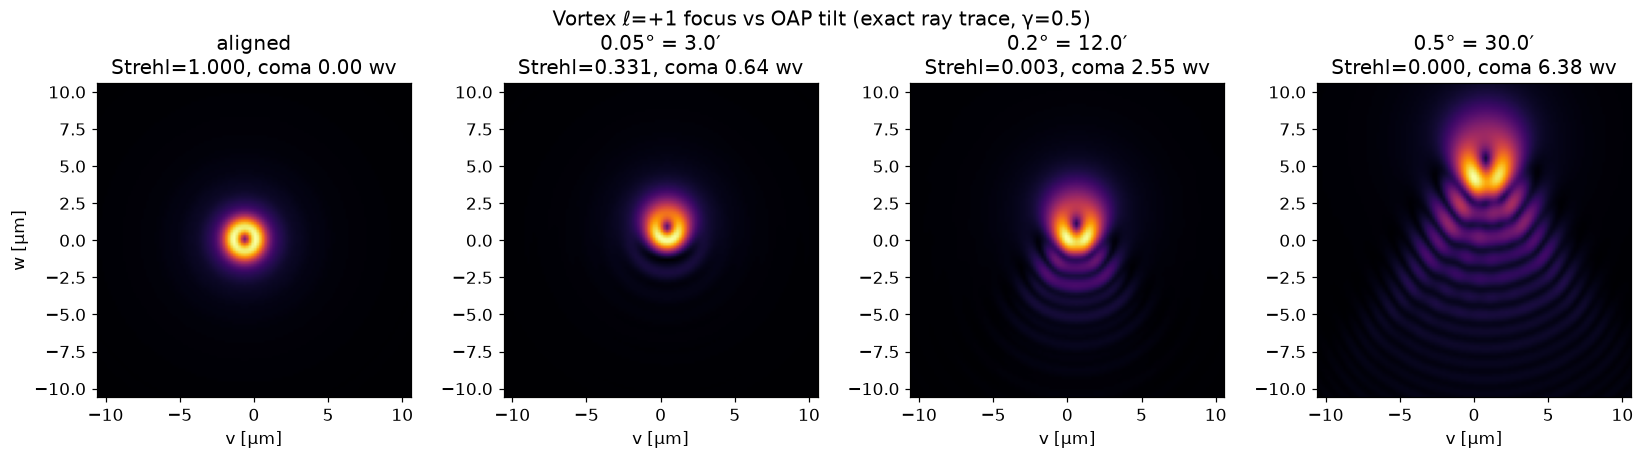

In [13]:
tilts = [0.0, 0.05, 0.2, 0.5]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.0), constrained_layout=True)
from matplotlib.colors import PowerNorm
for ax, deg in zip(axes, tilts):
    o = exact_oap(lambda X,Y: gauss(X,Y,l=1), deg, Lout=30e-6, Nout=170)
    I = np.abs(o['Ex'])**2+np.abs(o['Ey'])**2+np.abs(o['Ez'])**2
    # recentre display on the intensity peak
    iy,ix = np.unravel_index(np.argmax(I), I.shape)
    h = 60
    iy = min(max(iy,h), I.shape[0]-h); ix = min(max(ix,h), I.shape[1]-h)
    crop = I[iy-h:iy+h, ix-h:ix+h]; crop /= crop.max()
    dv = (o['vax'][1]-o['vax'][0])*1e6
    e2 = [-h*dv, h*dv, -h*dv, h*dv]
    im = ax.imshow(crop, origin='lower', extent=e2, cmap='inferno', norm=PowerNorm(0.5))
    lab = 'aligned' if deg==0 else f'{deg}° = {deg*60:.1f}′'
    ax.set_title(f"{lab}\nStrehl={o['strehl']:.3f}, coma {o['ptv']:.2f} wv")
    ax.set_xlabel('v [µm]')
axes[0].set_ylabel('w [µm]')
fig.suptitle('Vortex ℓ=+1 focus vs OAP tilt (exact ray trace, γ=0.5)', fontsize=13)
plt.show()

## 8. Quantitative tolerancing

Now the point of the notebook. We scan tilt, and for each compute the amplitude-weighted
**RMS wavefront** $\sigma$ (waves) and the **Strehl ratio**
$S=\bigl|\langle e^{i\varphi}\rangle\bigr|^2$. The **diffraction limit** is the Maréchal
criterion $S\ge0.8\Leftrightarrow \sigma\le\lambda/14\approx0.071$ waves. We read off the
tilt that reaches it.

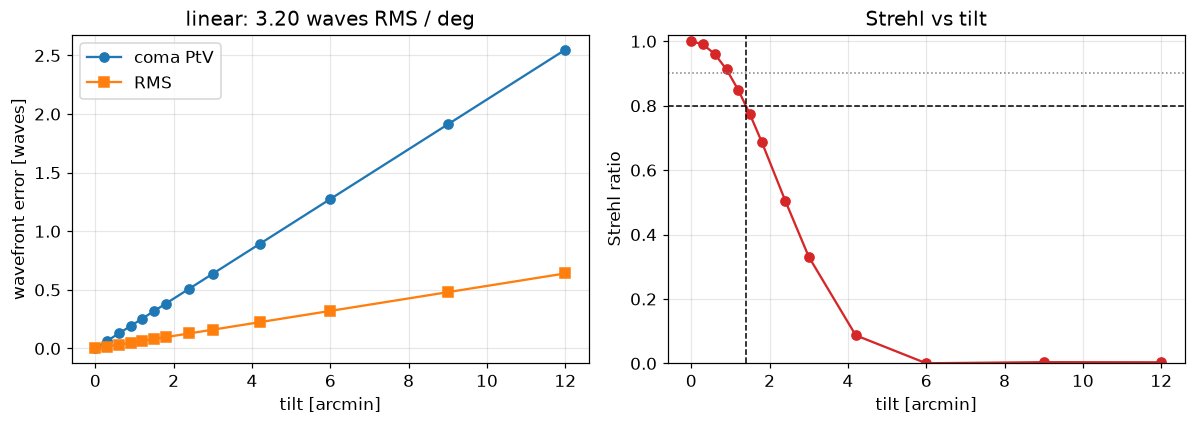

coma sensitivity      : 12.7 waves PtV / degree
RMS sensitivity       : 3.20 waves RMS / degree
diffraction limit S>=0.8 : tilt <= 1.41 arcmin  (23.5 mdeg)
tighter        S>=0.9 : tilt <= 0.97 arcmin  (16.1 mdeg)


In [28]:
degs = np.array([0,0.005,0.01,0.015,0.02,0.025,0.03,0.04,0.05,0.07,0.1,0.15,0.2])
rms = []; strehl = []; ptv = []
for d in degs:
    o = exact_oap(lambda X,Y: gauss(X,Y), d, Nout=60, Lout=30e-6)
    rms.append(o['rms']); strehl.append(o['strehl']); ptv.append(o['ptv'])
rms = np.array(rms); strehl = np.array(strehl); ptv = np.array(ptv)

# linear fits (coma is linear in field angle) and Strehl=0.8/0.9 crossings
slope_rms = np.polyfit(degs, rms, 1)[0]                  # waves per degree
slope_ptv = np.polyfit(degs, ptv, 1)[0]
sig80 = np.sqrt(-np.log(0.8))/(2*np.pi); sig90 = np.sqrt(-np.log(0.9))/(2*np.pi)
tol80 = sig80/slope_rms; tol90 = sig90/slope_rms

fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
ax[0].plot(degs*60, ptv, 'o-', label='coma PtV')
ax[0].plot(degs*60, rms, 's-', label='RMS')
ax[0].set_xlabel('tilt [arcmin]'); ax[0].set_ylabel('wavefront error [waves]')
ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title(f'linear: {slope_rms:.2f} waves RMS / deg')

ax[1].plot(degs*60, strehl, 'o-', color='C3')
ax[1].axhline(0.8, ls='--', c='k', lw=1); ax[1].axhline(0.9, ls=':', c='gray', lw=1)
ax[1].axvline(tol80*60, ls='--', c='k', lw=1)
ax[1].set_xlabel('tilt [arcmin]'); ax[1].set_ylabel('Strehl ratio')
ax[1].set_ylim(0,1.02); ax[1].grid(alpha=.3); ax[1].set_title('Strehl vs tilt')
plt.tight_layout(); plt.show()

print(f"coma sensitivity      : {slope_ptv:.1f} waves PtV / degree")
print(f"RMS sensitivity       : {slope_rms:.2f} waves RMS / degree")
print(f"diffraction limit S>=0.8 : tilt <= {tol80*60:.2f} arcmin  ({tol80*1e3:.1f} mdeg)")
print(f"tighter        S>=0.9 : tilt <= {tol90*60:.2f} arcmin  ({tol90*1e3:.1f} mdeg)")

## Summary

* The focus is built from the exact 3-D geometry with a **closed-form ray/surface
  intersection** — the pupil-coordinate approximation is gone, so the wavefront (and
  therefore the tolerancing) is quantitative.
* Coma grows **linearly** with tilt; the RMS-wavefront slope sets a hard
  diffraction-limited tilt budget of a **couple of arcminutes** for this fast
  ($f/\#\approx1.2$) optic.

**Caveats to keep honest.** (1) Ideal-conductor reflection (no Fresnel $s/p$ phase);
(2) still the on-axis parent, not yet the off-centre commercial sub-aperture — feed the
real mechanical $R,\mathbf t$ and mask the sub-aperture to tolerance the actual optic;
(3) the Strehl is at the least-squares (best) focus; a fixed-plane detector would see a
lower Strehl. (4) The $O(N_{\text{pupil}}N_{\text{out}})$ sum is exact but not fast —
swap in a NUFFT for large sweeps.